In [17]:
!zip -r unetpp_GLaS_mod_2_outputs.zip /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs

  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/ (stored 0%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/test_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/dataset_split_manifest.csv (deflated 93%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/validation_metrics_summary.csv (deflated 38%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/test_metrics_per_image.png (deflated 5%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/validation_metrics_per_image.png (deflated 6%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/validation_metrics_macro_average.png (deflated 22%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/best_inference.weights.h5 (deflated 8%)
  adding: content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/test_metrics_sum

In [1]:
!unzip -q /content/GLaS.zip -d /content/

In [13]:
import os
import random
import numpy as np
import cv2
import matplotlib.pyplot as plt
import pandas as pd
import tensorflow as tf
from tensorflow.keras import layers, Model
from google.colab import drive


IMG_SIZE = (256, 256)
BATCH_SIZE = 2
EPOCHS = 50
SEED = 42
BOUNDARY_TOLERANCE = 2
PRED_THRESHOLD = 0.5
DATASET_ROOT = "/content/Warwick_QU_Dataset"

train_image_dir = os.path.join(DATASET_ROOT, "train", "img")
train_mask_dir = os.path.join(DATASET_ROOT, "train", "mask")

val_image_dir = os.path.join(DATASET_ROOT, "val", "img")
val_mask_dir = os.path.join(DATASET_ROOT, "val", "mask")

test_image_dir = os.path.join(DATASET_ROOT, "test", "img")
test_mask_dir = os.path.join(DATASET_ROOT, "test", "mask")
OUTPUT_DIR = '/content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs'
MODEL_LABEL = 'U-Net++ Modification 2 — Fixed Kernels'
BASE_FILTERS = [32, 64, 128, 256, 512]
os.makedirs(OUTPUT_DIR, exist_ok=True)

for directory in (
    train_image_dir, train_mask_dir,
    val_image_dir, val_mask_dir,
    test_image_dir, test_mask_dir,
):
    if not os.path.isdir(directory):
        raise FileNotFoundError(f"Required dataset directory not found: {directory}")

tf.keras.utils.set_random_seed(SEED)
np.random.seed(SEED)
random.seed(SEED)
AUTOTUNE = tf.data.AUTOTUNE
gpus = tf.config.list_physical_devices("GPU")
print("TensorFlow:", tf.__version__)
print("Visible GPUs:", gpus)
if not gpus:
    raise RuntimeError("No GPU detected. Select Runtime > Change runtime type > GPU in Colab.")
for gpu in gpus:
    try:
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError:
        pass
print("Dataset root:", DATASET_ROOT)
print("Train image/mask:", train_image_dir, train_mask_dir)
print("Validation image/mask:", val_image_dir, val_mask_dir)
print("Test image/mask:", test_image_dir, test_mask_dir)
print("Output directory:", OUTPUT_DIR)


TensorFlow: 2.21.0
Visible GPUs: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]
Dataset root: /content/Warwick_QU_Dataset
Train image/mask: /content/Warwick_QU_Dataset/train/img /content/Warwick_QU_Dataset/train/mask
Validation image/mask: /content/Warwick_QU_Dataset/val/img /content/Warwick_QU_Dataset/val/mask
Test image/mask: /content/Warwick_QU_Dataset/test/img /content/Warwick_QU_Dataset/test/mask
Output directory: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs


In [14]:
def get_pairs(image_dir, mask_dir):
    valid_extensions = {".jpg", ".jpeg", ".png", ".bmp", ".tif", ".tiff"}

    def collect_files(directory, is_mask=False):
        files = {}

        if not os.path.isdir(directory):
            raise FileNotFoundError(f"Directory not found: {directory}")

        for name in sorted(os.listdir(directory)):
            path = os.path.join(directory, name)

            if not os.path.isfile(path):
                continue

            stem, ext = os.path.splitext(name)

            if ext.lower() not in valid_extensions:
                continue

            # Remove the '_anno' suffix from mask filenames.
            if is_mask and stem.lower().endswith("_anno"):
                stem = stem[:-5]

            key = stem.casefold()

            if key in files:
                raise ValueError(f"Duplicate filename after normalization: {name}")

            files[key] = path

        return files

    image_files = collect_files(image_dir)
    mask_files = collect_files(mask_dir, is_mask=True)

    missing_masks = sorted(set(image_files) - set(mask_files))
    orphan_masks = sorted(set(mask_files) - set(image_files))

    if missing_masks or orphan_masks:
        raise ValueError(
            f"Image/mask pairing is incomplete.\n"
            f"Images without masks: {missing_masks[:10]}\n"
            f"Masks without images: {orphan_masks[:10]}"
        )

    return [
        (image_files[key], mask_files[key])
        for key in sorted(image_files)
    ]


def _decode_path(path):
    if isinstance(path, np.ndarray):
        path = path.item()
    return os.fsdecode(path)


def load_image_mask(img_path, mask_path):
    img_path = _decode_path(img_path)
    mask_path = _decode_path(mask_path)

    image = cv2.imread(img_path, cv2.IMREAD_COLOR)
    mask = cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE)

    if image is None:
        raise ValueError(f"Could not read image: {img_path}")
    if mask is None:
        raise ValueError(f"Could not read mask: {mask_path}")

    image = cv2.cvtColor(image, cv2.COLOR_BGR2RGB)
    image = cv2.resize(
        image, IMG_SIZE, interpolation=cv2.INTER_AREA
    ).astype(np.float32) / 255.0

    mask = cv2.resize(mask, IMG_SIZE, interpolation=cv2.INTER_NEAREST)
    threshold = 0 if mask.max(initial=0) <= 1 else 127
    mask = (mask > threshold).astype(np.float32)[..., np.newaxis]

    return image, mask


def tf_load_image_mask(img_path, mask_path):
    image, mask = tf.numpy_function(
        func=load_image_mask,
        inp=[img_path, mask_path],
        Tout=[tf.float32, tf.float32],
    )
    image.set_shape([IMG_SIZE[0], IMG_SIZE[1], 3])
    mask.set_shape([IMG_SIZE[0], IMG_SIZE[1], 1])
    return image, mask


def augment(image, mask):
    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_left_right(image)
        mask = tf.image.flip_left_right(mask)

    if tf.random.uniform(()) > 0.5:
        image = tf.image.flip_up_down(image)
        mask = tf.image.flip_up_down(mask)

    rotations = tf.random.uniform((), minval=0, maxval=4, dtype=tf.int32)
    return tf.image.rot90(image, rotations), tf.image.rot90(mask, rotations)


def duplicate_mask(image, mask):
    # Four identical masks are required by the four-output deep-supervision models.
    return image, (mask, mask, mask, mask)


def make_dataset(split_pairs, training=False, duplicate=False):
    if not split_pairs:
        raise ValueError("Cannot create a dataset from an empty split.")

    image_paths = [pair[0] for pair in split_pairs]
    mask_paths = [pair[1] for pair in split_pairs]

    dataset = tf.data.Dataset.from_tensor_slices((image_paths, mask_paths))

    if training:
        dataset = dataset.shuffle(
            buffer_size=len(split_pairs),
            seed=SEED,
            reshuffle_each_iteration=True,
        )

    dataset = dataset.map(tf_load_image_mask, num_parallel_calls=AUTOTUNE)

    if training:
        dataset = dataset.map(augment, num_parallel_calls=AUTOTUNE)

    if duplicate:
        dataset = dataset.map(duplicate_mask, num_parallel_calls=AUTOTUNE)

    return dataset.batch(BATCH_SIZE).prefetch(AUTOTUNE)


# Use the dataset's existing train/val/test folders. No re-splitting is performed.
train_pairs = get_pairs(train_image_dir, train_mask_dir)
val_pairs = get_pairs(val_image_dir, val_mask_dir)
test_pairs = get_pairs(test_image_dir, test_mask_dir)

if not train_pairs or not val_pairs or not test_pairs:
    raise ValueError(
        "Each existing split must contain at least one correctly paired image and mask. "
        f"Found train={len(train_pairs)}, val={len(val_pairs)}, test={len(test_pairs)}."
    )

split_pairs = {
    "train": train_pairs,
    "validation": val_pairs,
    "test": test_pairs,
}

# Ensure the same image path has not accidentally been assigned to multiple splits.
split_keys = {
    name: {os.path.abspath(image_path) for image_path, _ in split}
    for name, split in split_pairs.items()
}
if any(
    split_keys[a] & split_keys[b]
    for a, b in (
        ("train", "validation"),
        ("train", "test"),
        ("validation", "test"),
    )
):
    raise AssertionError(
        "The provided dataset has overlapping image paths between splits. "
        "Check the train, val, and test directory assignments."
    )

pairs = train_pairs + val_pairs + test_pairs

manifest_rows = [
    {
        "split": split_name,
        "image": image_path,
        "mask": mask_path,
        "image_filename": os.path.basename(image_path),
    }
    for split_name, split in split_pairs.items()
    for image_path, mask_path in sorted(split, key=lambda pair: pair[0])
]

manifest_path = os.path.join(OUTPUT_DIR, "dataset_split_manifest.csv")
pd.DataFrame(manifest_rows).to_csv(manifest_path, index=False)

# Deep-supervision training datasets: the models expect four mask outputs.
train_ds_multi = make_dataset(train_pairs, training=True, duplicate=True)
val_ds_multi = make_dataset(val_pairs, training=False, duplicate=True)

# Single-output datasets are used by validation callbacks and test evaluation.
val_ds_single = make_dataset(val_pairs, training=False)
test_ds_single = make_dataset(test_pairs, training=False)

print("Using the dataset's existing splits; no samples were reallocated.")
for split_name, split in split_pairs.items():
    print(f"{split_name.title():12s}: {len(split):4d} images")
print(f"Total paired samples: {len(pairs)}")
print(f"Saved split manifest: {manifest_path}")


Using the dataset's existing splits; no samples were reallocated.
Train       :  133 images
Validation  :   16 images
Test        :   16 images
Total paired samples: 165
Saved split manifest: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/dataset_split_manifest.csv


Model: "UNetPlusPlus_FixedKernel_Train"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_18 (ReLU)     │ (None, 256, 256,  │          0 │ conv2d_19[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      9,248 │ re_lu_18[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 256, 256,  │          0 │ conv2d_20[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ re_lu_19[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 128, 128,  │          0 │ conv2d_21[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │     36,928 │ re_lu_20[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_21 (ReLU)     │ (None, 128, 128,  │          0 │ conv2d_22[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ re_lu_21[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_22 (ReLU)     │ (None, 64, 64,    │          0 │ conv2d_23[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │    147,584 │ re_lu_22[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_23 (ReLU)     │ (None, 64, 64,    │          0 │ conv2d_24[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ re_lu_23[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_6[

 Total params: 8,754,340 (33.40 MB)

 Trainable params: 8,754,340 (33.40 MB)

 Non-trainable params: 0 (0.00 B)

Model: "UNetPlusPlus_FixedKernel_Infer"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 256, 256,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_19 (Conv2D)  │ (None, 256, 256,  │        896 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_18 (ReLU)     │ (None, 256, 256,  │          0 │ conv2d_19[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_20 (Conv2D)  │ (None, 256, 256,  │      9,248 │ re_lu_18[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_19 (ReLU)     │ (None, 256, 256,  │          0 │ conv2d_20[0][0]   │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_4     │ (None, 128, 128,  │          0 │ re_lu_19[0][0]    │
│ (MaxPooling2D)      │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_21 (Conv2D)  │ (None, 128, 128,  │     18,496 │ max_pooling2d_4[… │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_20 (ReLU)     │ (None, 128, 128,  │          0 │ conv2d_21[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_22 (Conv2D)  │ (None, 128, 128,  │     36,928 │ re_lu_20[0][0]    │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_21 (ReLU)     │ (None, 128, 128,  │          0 │ conv2d_22[0][0]   │
│                     │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_5     │ (None, 64, 64,    │          0 │ re_lu_21[0][0]    │
│ (MaxPooling2D)      │ 64)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_23 (Conv2D)  │ (None, 64, 64,    │     73,856 │ max_pooling2d_5[… │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_22 (ReLU)     │ (None, 64, 64,    │          0 │ conv2d_23[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_24 (Conv2D)  │ (None, 64, 64,    │    147,584 │ re_lu_22[0][0]    │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ re_lu_23 (ReLU)     │ (None, 64, 64,    │          0 │ conv2d_24[0][0]   │
│                     │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ max_pooling2d_6     │ (None, 32, 32,    │          0 │ re_lu_23[0][0]    │
│ (MaxPooling2D)      │ 128)              │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ conv2d_25 (Conv2D)  │ (None, 32, 32,    │    295,168 │ max_pooling2d_6[

 Total params: 8,754,340 (33.40 MB)

 Trainable params: 8,754,340 (33.40 MB)

 Non-trainable params: 0 (0.00 B)

Epoch 1/50
67/67 ━━━━━━━━━━━━━━━━━━━━ 0s 488ms/step - loss: 0.8291 - side_1_accuracy: 0.5066 - side_1_dice_coef: 0.5537 - side_1_iou_coef: 0.3857 - side_1_loss: 0.8210 - side_2_accuracy: 0.5075 - side_2_dice_coef: 0.5531 - side_2_iou_coef: 0.3847 - side_2_loss: 0.8191 - side_3_accuracy: 0.5133 - side_3_dice_coef: 0.5619 - side_3_iou_coef: 0.3939 - side_3_loss: 0.8261 - side_4_accuracy: 0.5150 - side_4_dice_coef: 0.5642 - side_4_iou_coef: 0.3956 - side_4_loss: 0.8504
val_avg_loss=0.8204 val_avg_dice_coef=0.5528 val_avg_iou_coef=0.3871
Saved best inference weights: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/best_inference.weights.h5
67/67 ━━━━━━━━━━━━━━━━━━━━ 80s 658ms/step - loss: 0.8156 - side_1_accuracy: 0.5088 - side_1_dice_coef: 0.5572 - side_1_iou_coef: 0.3896 - side_1_loss: 0.8164 - side_2_accuracy: 0.5074 - side_2_dice_coef: 0.5565 - side_2_iou_coef: 0.3889 - side_2_loss: 0.8142 - side_3_accuracy: 0.5155 - side_3_dice_coef: 0.5619 - side_3_iou_coef: 0.3943 - 

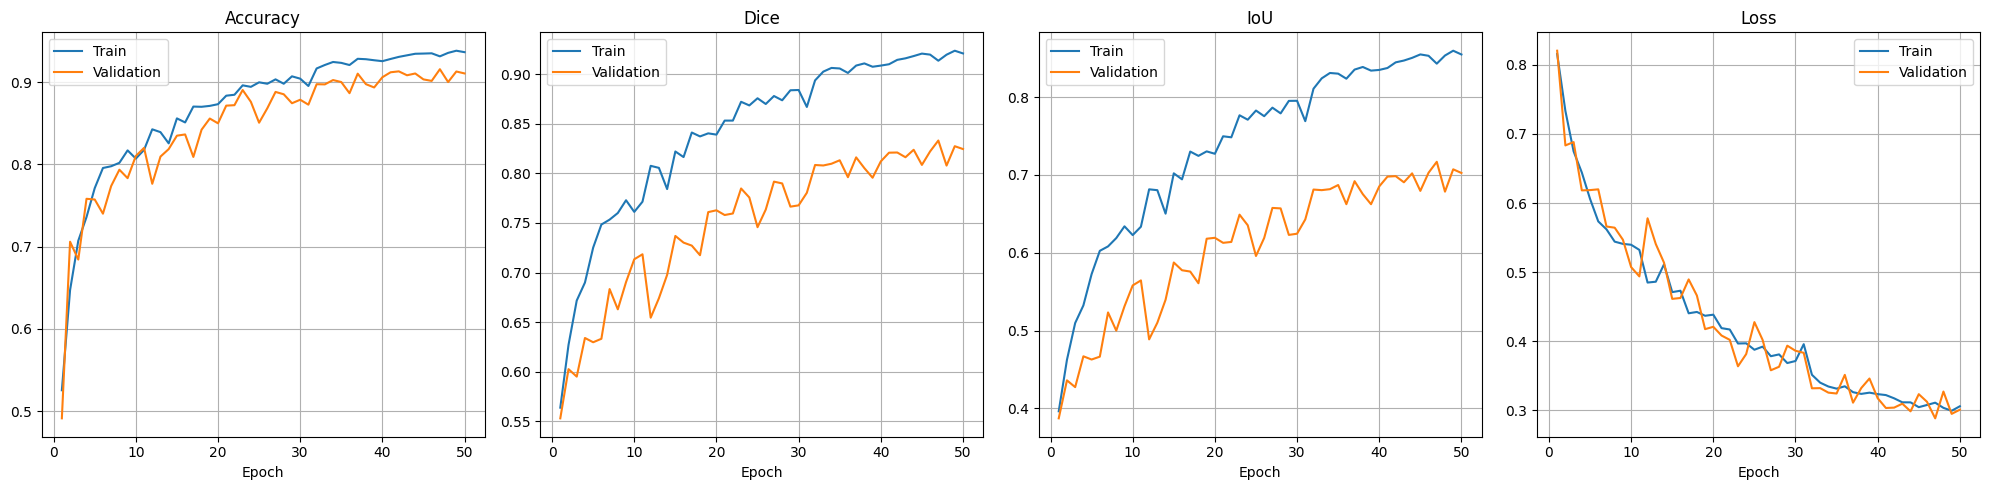

Best inference weights: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/best_inference.weights.h5


In [15]:
bce_loss_fn = tf.keras.losses.BinaryCrossentropy()

def dice_coef(y_true, y_pred, smooth=1e-07):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    return (2.0 * intersection + smooth) / (tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) + smooth)

def dice_loss(y_true, y_pred):
    return 1.0 - dice_coef(y_true, y_pred)

def combined_bce_dice_loss(y_true, y_pred):
    bce = bce_loss_fn(y_true, y_pred)
    dloss = dice_loss(y_true, y_pred)
    return 0.5 * bce + dloss

def iou_coef(y_true, y_pred, smooth=1e-07):
    y_true_f = tf.keras.backend.flatten(tf.cast(y_true, tf.float32))
    y_pred_f = tf.keras.backend.flatten(tf.cast(y_pred, tf.float32))
    intersection = tf.reduce_sum(y_true_f * y_pred_f)
    union = tf.reduce_sum(y_true_f) + tf.reduce_sum(y_pred_f) - intersection
    return (intersection + smooth) / (union + smooth)

def conv_block(x, filters):
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal')(x)
    x = layers.ReLU()(x)
    x = layers.Conv2D(filters, 3, padding='same', kernel_initializer='he_normal')(x)
    x = layers.ReLU()(x)
    return x

@tf.keras.utils.register_keras_serializable(package='RockSegmentation')
class FixedKernelLayer(layers.Layer):

    def __init__(self, **kwargs):
        kwargs.pop('trainable', None)
        super().__init__(trainable=False, **kwargs)

    def build(self, input_shape):
        c = int(input_shape[-1])
        sobel_x = np.array([[-1, 0, 1], [-2, 0, 2], [-1, 0, 1]], dtype=np.float32)
        sobel_y = np.array([[-1, -2, -1], [0, 0, 0], [1, 2, 1]], dtype=np.float32)
        laplacian = np.array([[0, 1, 0], [1, -4, 1], [0, 1, 0]], dtype=np.float32)

        def make_depthwise_kernel(base_kernel):
            k = np.zeros((3, 3, c, 1), dtype=np.float32)
            for ch in range(c):
                k[:, :, ch, 0] = base_kernel
            return tf.constant(k)
        self.k_sobel_x = make_depthwise_kernel(sobel_x)
        self.k_sobel_y = make_depthwise_kernel(sobel_y)
        self.k_lap = make_depthwise_kernel(laplacian)
        super().build(input_shape)

    def call(self, x):
        sx = tf.nn.depthwise_conv2d(x, self.k_sobel_x, strides=[1, 1, 1, 1], padding='SAME')
        sy = tf.nn.depthwise_conv2d(x, self.k_sobel_y, strides=[1, 1, 1, 1], padding='SAME')
        lp = tf.nn.depthwise_conv2d(x, self.k_lap, strides=[1, 1, 1, 1], padding='SAME')
        return tf.concat([sx, sy, lp], axis=-1)

def merge_with_fixed_kernels(inputs_list, filters, prefix):
    original_feats = inputs_list
    fixed_feats = []
    for idx, feat in enumerate(original_feats):
        fk = FixedKernelLayer(name=f'{prefix}_fixed_{idx}')(feat)
        fixed_feats.append(fk)
    x = layers.Concatenate(name=f'{prefix}_concat')(original_feats + fixed_feats)
    x = layers.Conv2D(filters, 1, padding='same', kernel_initializer='he_normal', name=f'{prefix}_compress')(x)
    x = layers.ReLU(name=f'{prefix}_compress_relu')(x)
    return x

def build_unet_plus_plus_fixed(input_shape=(256, 256, 3)):
    filters = BASE_FILTERS
    depth = len(filters) - 1
    inputs = layers.Input(shape=input_shape)
    X = {}
    x = inputs
    for i in range(depth + 1):
        X[i, 0] = conv_block(x, filters[i])
        if i < depth:
            x = layers.MaxPooling2D((2, 2))(X[i, 0])
    for j in range(1, depth + 1):
        for i in range(0, depth - j + 1):
            up = layers.Conv2DTranspose(filters[i], kernel_size=2, strides=2, padding='same', name=f'up_{i}_{j}')(X[i + 1, j - 1])
            base_feats = [X[i, k] for k in range(j)] + [up]
            merged = merge_with_fixed_kernels(base_feats, filters[i], prefix=f'merge_{i}_{j}')
            X[i, j] = conv_block(merged, filters[i])
    side_outputs = [layers.Conv2D(1, 1, activation='sigmoid', name=f'side_{j}')(X[0, j]) for j in range(1, depth + 1)]
    train_model = Model(inputs, side_outputs, name='UNetPlusPlus_FixedKernel_Train')
    avg_output = layers.Average(name='avg_output')(side_outputs)
    infer_model = Model(inputs, avg_output, name='UNetPlusPlus_FixedKernel_Infer')
    return (train_model, infer_model)

train_model, infer_model = build_unet_plus_plus_fixed((IMG_SIZE[0], IMG_SIZE[1], 3))
train_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=[combined_bce_dice_loss] * 4,
    loss_weights=[0.25] * 4,
    metrics=[["accuracy", dice_coef, iou_coef] for _ in range(4)],
)
infer_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=3e-4),
    loss=combined_bce_dice_loss,
    metrics=["accuracy", dice_coef, iou_coef],
)

BEST_WEIGHTS_PATH = os.path.join(OUTPUT_DIR, "best_inference.weights.h5")

def metric_value(results, name):
    if name in results:
        return results[name]
    matches = [value for key, value in results.items() if key.endswith("_" + name)]
    if matches:
        return matches[0]
    raise KeyError(f"Metric {name} was not found in evaluation results: {list(results)}")

class EvaluateAndSaveBest(tf.keras.callbacks.Callback):
    def __init__(self, inference_model, validation_dataset, checkpoint_path):
        super().__init__()
        self.inference_model = inference_model
        self.validation_dataset = validation_dataset
        self.checkpoint_path = checkpoint_path
        self.best_dice = -np.inf

    def on_epoch_end(self, epoch, logs=None):
        logs = logs if logs is not None else {}
        results = self.inference_model.evaluate(self.validation_dataset, verbose=0, return_dict=True)
        for key in ("loss", "accuracy", "dice_coef", "iou_coef"):
            logs[f"val_avg_{key}"] = float(metric_value(results, key))
        current_dice = logs["val_avg_dice_coef"]
        print(f"\nval_avg_loss={logs['val_avg_loss']:.4f} val_avg_dice_coef={current_dice:.4f} val_avg_iou_coef={logs['val_avg_iou_coef']:.4f}")
        if current_dice > self.best_dice:
            self.best_dice = current_dice
            self.inference_model.save_weights(self.checkpoint_path)
            print("Saved best inference weights:", self.checkpoint_path)

best_callback = EvaluateAndSaveBest(infer_model, val_ds_single, BEST_WEIGHTS_PATH)
early_stopping = tf.keras.callbacks.EarlyStopping(
    monitor="val_avg_dice_coef", mode="max", patience=10, restore_best_weights=True, verbose=1
)
reduce_lr = tf.keras.callbacks.ReduceLROnPlateau(
    monitor="val_avg_dice_coef", mode="max", factor=0.5, patience=4, verbose=1
)

train_model.summary()
infer_model.summary()
history = train_model.fit(
    train_ds_multi,
    validation_data=val_ds_multi,
    epochs=EPOCHS,
    callbacks=[best_callback, early_stopping, reduce_lr],
)
infer_model.load_weights(BEST_WEIGHTS_PATH)

hist = history.history
epoch_numbers = np.arange(1, len(hist["loss"]) + 1)
fig, axes = plt.subplots(1, 4, figsize=(20, 5))
curve_settings = [
    ("side_4_accuracy", "val_avg_accuracy", "Accuracy"),
    ("side_4_dice_coef", "val_avg_dice_coef", "Dice"),
    ("side_4_iou_coef", "val_avg_iou_coef", "IoU"),
    ("loss", "val_avg_loss", "Loss"),
]
for ax, (train_key, val_key, title) in zip(axes, curve_settings):
    if train_key in hist:
        ax.plot(epoch_numbers, hist[train_key], label="Train")
    if val_key in hist:
        ax.plot(epoch_numbers, hist[val_key], label="Validation")
    ax.set_title(title)
    ax.set_xlabel("Epoch")
    ax.grid(True)
    ax.legend()
plt.tight_layout()
plt.savefig(os.path.join(OUTPUT_DIR, "training_curves.png"), dpi=200, bbox_inches="tight")
plt.show()
print("Best inference weights:", BEST_WEIGHTS_PATH)


Validation image 1/16: testA_1.png
Validation image 2/16: testA_10.png
Validation image 3/16: testA_11.png
Validation image 4/16: testA_12.png
Validation image 5/16: testA_13.png
Validation image 6/16: testA_14.png
Validation image 7/16: testA_15.png
Validation image 8/16: testA_16.png
Validation image 9/16: testA_2.png
Validation image 10/16: testA_3.png
Validation image 11/16: testA_4.png
Validation image 12/16: testA_5.png
Validation image 13/16: testA_6.png
Validation image 14/16: testA_7.png
Validation image 15/16: testA_8.png
Validation image 16/16: testA_9.png

U-Net++ Modification 2 — Fixed Kernels — VALIDATION MACRO METRICS OVER 16 IMAGES
IoU                     : 0.8250 ± 0.1159
Recall                  : 0.9366 ± 0.0506
Precision               : 0.8764 ± 0.1244
Dice Coefficient        : 0.8996 ± 0.0753
Boundary F1             : 0.7237 ± 0.1455
Boundary Recall         : 0.8167 ± 0.0854
Boundary Precision      : 0.6674 ± 0.1872


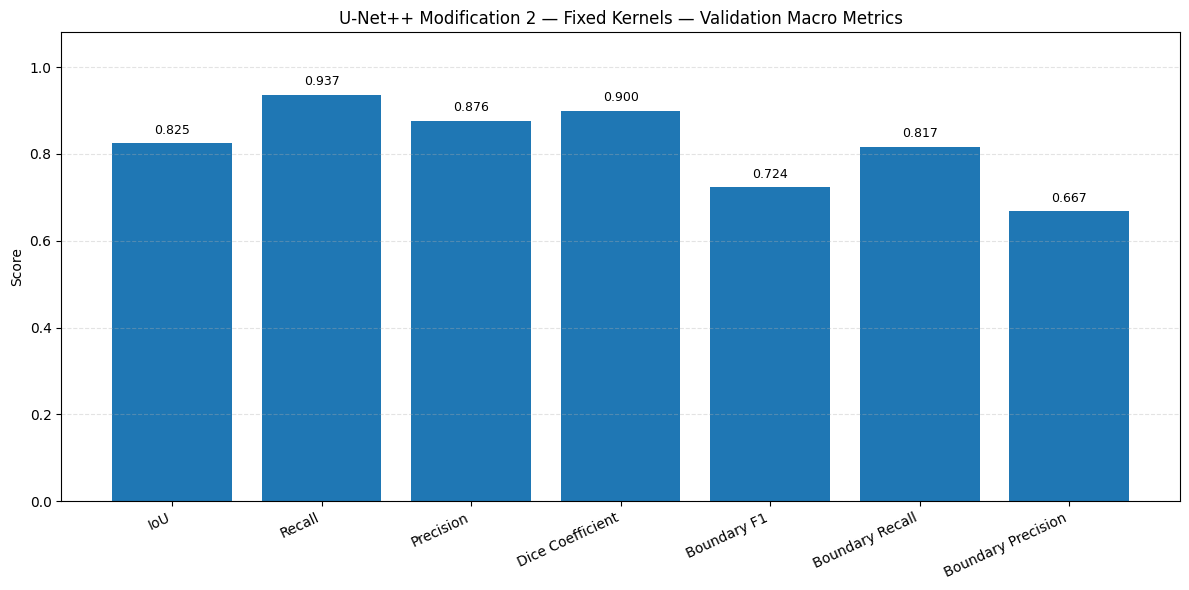

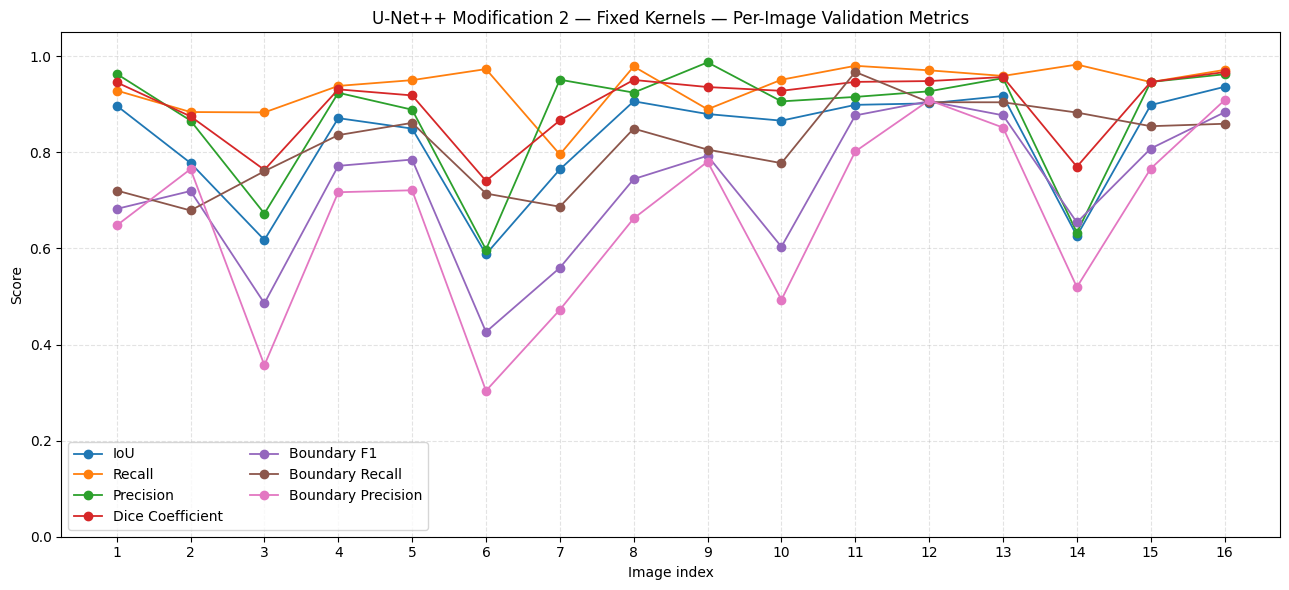

Saved metrics and plots in: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs
Test image 1/16: testB_1.png
Test image 2/16: testB_10.png
Test image 3/16: testB_11.png
Test image 4/16: testB_12.png
Test image 5/16: testB_13.png
Test image 6/16: testB_14.png
Test image 7/16: testB_15.png
Test image 8/16: testB_16.png
Test image 9/16: testB_2.png
Test image 10/16: testB_3.png
Test image 11/16: testB_4.png
Test image 12/16: testB_5.png
Test image 13/16: testB_6.png
Test image 14/16: testB_7.png
Test image 15/16: testB_8.png
Test image 16/16: testB_9.png

U-Net++ Modification 2 — Fixed Kernels — TEST MACRO METRICS OVER 16 IMAGES
IoU                     : 0.7715 ± 0.1197
Recall                  : 0.9386 ± 0.0881
Precision               : 0.8156 ± 0.1136
Dice Coefficient        : 0.8661 ± 0.0776
Boundary F1             : 0.5997 ± 0.1630
Boundary Recall         : 0.6948 ± 0.1787
Boundary Precision      : 0.5379 ± 0.1664


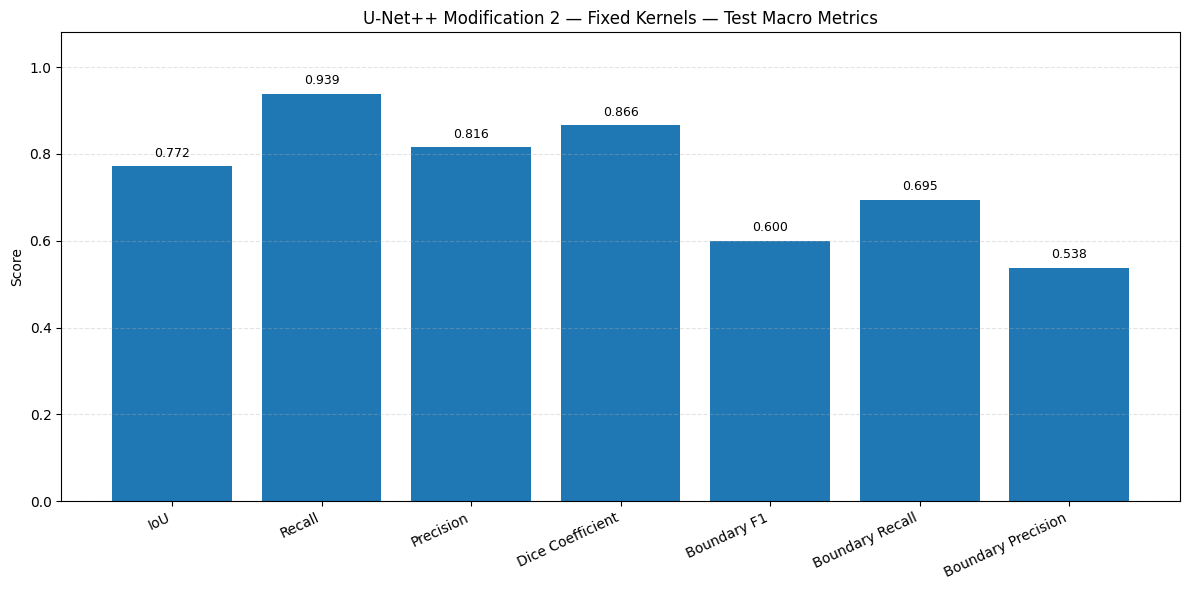

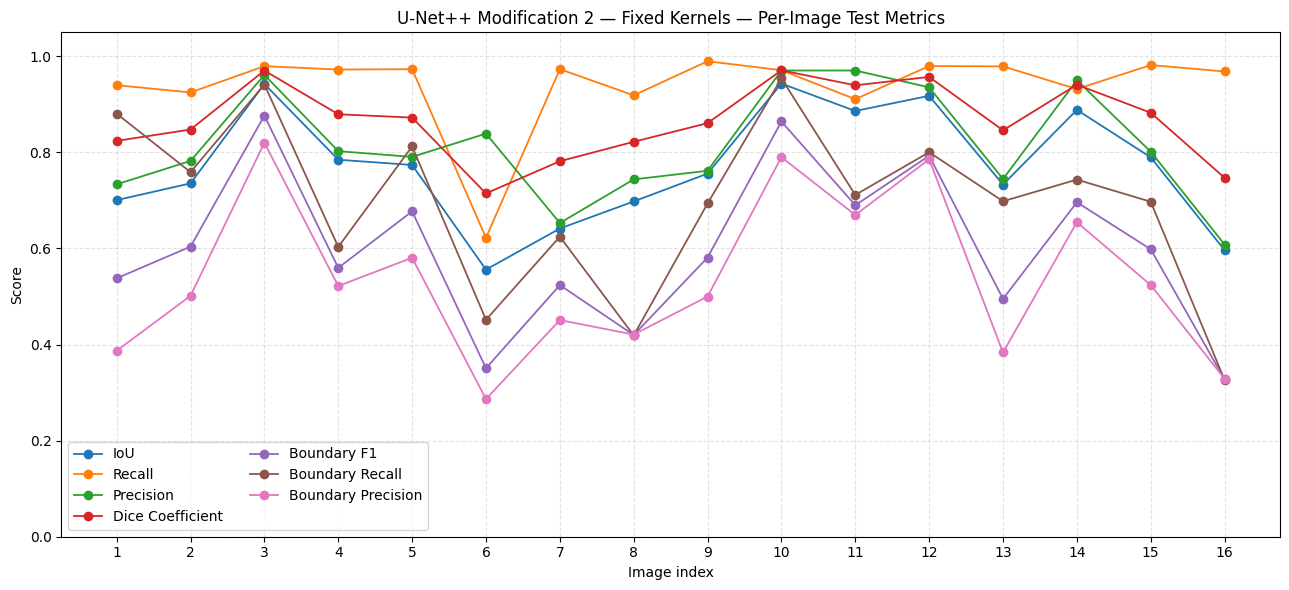

Saved metrics and plots in: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs
Saved test predicted masks in: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/test_predicted_masks
TEST EVALUATION COMPLETE.
Held-out test predicted masks: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/test_predicted_masks
Dataset split manifest: /content/drive/MyDrive/unetpp_our_data_mod2_fixedkernel_outputs/dataset_split_manifest.csv


In [16]:
METRIC_NAMES = ["iou", "recall", "precision", "dice_coef", "boundary_f1", "boundary_recall", "boundary_precision"]
DISPLAY_NAMES = {
    "iou": "IoU",
    "recall": "Recall",
    "precision": "Precision",
    "dice_coef": "Dice Coefficient",
    "boundary_f1": "Boundary F1",
    "boundary_recall": "Boundary Recall",
    "boundary_precision": "Boundary Precision",
}


def extract_binary_boundary(binary_mask):
    mask = (np.asarray(binary_mask).squeeze() > 0).astype(np.uint8)
    eroded = cv2.erode(mask, np.ones((3, 3), dtype=np.uint8), iterations=1, borderType=cv2.BORDER_CONSTANT, borderValue=0)
    return (mask - eroded).astype(np.uint8)


def segmentation_scores(gt_mask, pred_mask, tolerance=BOUNDARY_TOLERANCE):
    gt = (np.asarray(gt_mask).squeeze() > 0.5).astype(np.uint8)
    pred = (np.asarray(pred_mask).squeeze() > 0).astype(np.uint8)
    if gt.shape != pred.shape:
        raise ValueError(f"Mask shape mismatch: GT {gt.shape}, prediction {pred.shape}")
    tp = int(np.sum((gt == 1) & (pred == 1)))
    fp = int(np.sum((gt == 0) & (pred == 1)))
    fn = int(np.sum((gt == 1) & (pred == 0)))
    precision = tp / (tp + fp) if tp + fp else (1.0 if tp + fn == 0 else 0.0)
    recall = tp / (tp + fn) if tp + fn else (1.0 if tp + fp == 0 else 0.0)
    dice_den = 2 * tp + fp + fn
    iou_den = tp + fp + fn
    dice = 2 * tp / dice_den if dice_den else 1.0
    iou = tp / iou_den if iou_den else 1.0
    gt_boundary = extract_binary_boundary(gt)
    pred_boundary = extract_binary_boundary(pred)
    tolerance = max(0, int(tolerance))
    if tolerance:
        kernel_size = 2 * tolerance + 1
        kernel = cv2.getStructuringElement(cv2.MORPH_ELLIPSE, (kernel_size, kernel_size))
        gt_dilated = cv2.dilate(gt_boundary, kernel, iterations=1)
        pred_dilated = cv2.dilate(pred_boundary, kernel, iterations=1)
    else:
        gt_dilated, pred_dilated = gt_boundary, pred_boundary
    matched_pred = int(np.sum((pred_boundary > 0) & (gt_dilated > 0)))
    matched_gt = int(np.sum((gt_boundary > 0) & (pred_dilated > 0)))
    pred_count = int(pred_boundary.sum())
    gt_count = int(gt_boundary.sum())
    boundary_precision = matched_pred / pred_count if pred_count else (1.0 if gt_count == 0 else 0.0)
    boundary_recall = matched_gt / gt_count if gt_count else (1.0 if pred_count == 0 else 0.0)
    boundary_sum = boundary_precision + boundary_recall
    boundary_f1 = 2 * boundary_precision * boundary_recall / boundary_sum if boundary_sum else 0.0
    return {
        "iou": float(iou),
        "recall": float(recall),
        "precision": float(precision),
        "dice_coef": float(dice),
        "boundary_f1": float(boundary_f1),
        "boundary_recall": float(boundary_recall),
        "boundary_precision": float(boundary_precision),
    }


def evaluate_split(split_pairs, split_name, save_predictions=False):
    if not split_pairs:
        raise ValueError(f"The {split_name} split is empty.")
    prediction_dir = os.path.join(OUTPUT_DIR, f"{split_name}_predicted_masks")
    if save_predictions:
        os.makedirs(prediction_dir, exist_ok=True)
    rows = []
    for index, (image_path, mask_path) in enumerate(split_pairs, start=1):
        image, true_mask = load_image_mask(image_path, mask_path)
        predicted_probability = infer_model.predict(image[np.newaxis, ...], verbose=0)[0]
        predicted_mask = (np.asarray(predicted_probability).squeeze() >= PRED_THRESHOLD).astype(np.uint8)
        true_binary = (np.asarray(true_mask).squeeze() > 0.5).astype(np.uint8)
        scores = segmentation_scores(true_binary, predicted_mask, BOUNDARY_TOLERANCE)
        rows.append({"image": os.path.basename(image_path), **scores})
        if save_predictions:
            stem = os.path.splitext(os.path.basename(image_path))[0]
            output_path = os.path.join(prediction_dir, f"{stem}_pred.png")
            if not cv2.imwrite(output_path, predicted_mask * 255):
                raise IOError(f"Could not save predicted mask: {output_path}")
        print(f"{split_name.title()} image {index}/{len(split_pairs)}: {os.path.basename(image_path)}")
    results = pd.DataFrame(rows)
    means = results[METRIC_NAMES].mean()
    stds = results[METRIC_NAMES].std(ddof=1).fillna(0.0) if len(results) > 1 else means * 0.0
    summary = pd.DataFrame({
        "metric": [DISPLAY_NAMES[name] for name in METRIC_NAMES],
        "mean_score": [float(means[name]) for name in METRIC_NAMES],
        "std_score": [float(stds[name]) for name in METRIC_NAMES],
        "n_images": [len(results)] * len(METRIC_NAMES),
    })
    results.to_csv(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.csv"), index=False)
    summary.to_csv(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_summary.csv"), index=False)
    print("\n" + "=" * 64)
    print(f"{MODEL_LABEL} — {split_name.upper()} MACRO METRICS OVER {len(results)} IMAGES")
    for name in METRIC_NAMES:
        print(f"{DISPLAY_NAMES[name]:<24}: {means[name]:.4f} ± {stds[name]:.4f}")
    print("=" * 64)
    values = [float(means[name]) for name in METRIC_NAMES]
    labels = [DISPLAY_NAMES[name] for name in METRIC_NAMES]
    plt.figure(figsize=(12, 6))
    bars = plt.bar(labels, values)
    plt.ylim(0, 1.08)
    plt.ylabel("Score")
    plt.title(f"{MODEL_LABEL} — {split_name.title()} Macro Metrics")
    plt.xticks(rotation=25, ha="right")
    plt.grid(axis="y", linestyle="--", alpha=0.35)
    for bar, value in zip(bars, values):
        plt.text(bar.get_x() + bar.get_width() / 2, bar.get_height() + 0.015, f"{value:.3f}", ha="center", va="bottom", fontsize=9)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_macro_average.png"), dpi=200, bbox_inches="tight")
    plt.show()
    plt.figure(figsize=(13, 6))
    image_indices = np.arange(1, len(results) + 1)
    for name in METRIC_NAMES:
        plt.plot(image_indices, results[name], marker="o", linewidth=1.3, label=DISPLAY_NAMES[name])
    plt.ylim(0, 1.05)
    plt.xlabel("Image index")
    plt.ylabel("Score")
    plt.title(f"{MODEL_LABEL} — Per-Image {split_name.title()} Metrics")
    plt.xticks(image_indices)
    plt.grid(True, linestyle="--", alpha=0.35)
    plt.legend(ncol=2)
    plt.tight_layout()
    plt.savefig(os.path.join(OUTPUT_DIR, f"{split_name}_metrics_per_image.png"), dpi=200, bbox_inches="tight")
    plt.show()
    print("Saved metrics and plots in:", OUTPUT_DIR)
    if save_predictions:
        print("Saved test predicted masks in:", prediction_dir)
    return results, summary

validation_results, validation_summary = evaluate_split(val_pairs, "validation", save_predictions=False)
test_results, test_summary = evaluate_split(test_pairs, "test", save_predictions=True)
print("TEST EVALUATION COMPLETE.")
print("Held-out test predicted masks:", os.path.join(OUTPUT_DIR, "test_predicted_masks"))
print("Dataset split manifest:", manifest_path)
